## Speech Command classification

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import os
from concurrent.futures import ProcessPoolExecutor
from IPython.display import Audio
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from keras import backend as K
import keras_tuner as kt
from tensorflow.keras.callbacks import EarlyStopping
import json
import pywt
import pathlib
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import keras
from keras import layers, models, initializers
from sklearn.metrics import confusion_matrix
from scipy.spatial.distance import pdist, squareform
from matplotlib.colors import LinearSegmentedColormap
from tensorflow.keras import mixed_precision
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from reservoirpy.nodes import Reservoir
import reservoirpy as rpy
from tensorflow.keras.utils import plot_model
import tracemalloc
import psutil
import gc

rpy.verbosity(0)



# ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== #



plt.rcParams["figure.figsize"] = (15, 9)
my_yellow = '#D0E000'
my_red = '#A02000'
my_grey = '#303730'
my_blue = '#0020A0'
my_cmap = LinearSegmentedColormap.from_list("custom_cmap", [my_blue,'#80A030', my_yellow])




tf.config.optimizer.set_jit(True)


2025-02-15 18:56:33.833024: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-02-15 18:56:33.981166: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1739642194.038791    5364 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1739642194.055430    5364 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-02-15 18:56:34.186993: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

## Data overview

In [2]:
# main settings and configurations of the dataset

data_dir = '/home/kia/Desktop/PoD/HDA/data/speech_commands_v0.02'

dirlist = np.array(os.listdir(os.path.join(data_dir, 'training_data')))
exlist = np.array(['_background_noise_', '.DS_Store', 'README.md', 'LICENSE', 'testing_list.txt', 'validation_list.txt'])
wordlist = np.setdiff1d(dirlist, exlist)

full_dataset = True
filter = False
labels = ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']
if full_dataset:
  labels = wordlist


lab2int = {label: i for i, label in enumerate(labels)}
int2lab = {i: label for i, label in enumerate(labels)}



# ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== #


n_classes = len(labels)
sr = 16000
n_mels = 28
win_time = 60
hop_time = 40
win_length=int(sr*win_time/1000)
hop_length=int(sr*hop_time/1000)

settings = str(n_mels) + '_' + str(win_time) + '_' + str(hop_time)

# ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== # ==== #


noise_amp = 0.2
noise_dir = os.path.join(data_dir, '_background_noise_')

noise_paths = [os.path.join(noise_dir, fname) for fname in os.listdir(noise_dir) if fname != 'README.md']


noises = [librosa.util.normalize(librosa.load(noise_path, sr=sr)[0]) for noise_path in noise_paths]
noise_lengths = [len(noise) for noise in noises]


In [3]:
# preprocessing pipeline 

def process_audio_file(filepath, label, 
                       filter=filter, filter_length=sr, n_mels=n_mels, win_length=win_length, hop_length=hop_length, 
                       noise_amp=0.0, noises = noises, noise_lengths=noise_lengths):
    

    audio, sr = librosa.load(filepath, sr=16000, dtype=np.float32)
    length = len(audio)

    # Apply filtering based on length
    if filter and length < filter_length:
        return None  # Skip file file if it doesn't meet the length criteria

    # Padding if necessary
    if length < filter_length:
        padded = np.zeros(filter_length)
        start = (filter_length - length) // 2
        end = start + length
        padded[start:end] = audio
        audio = padded

    audio = librosa.util.normalize(audio)
    
    if noise_amp:
        ind = np.random.randint(len(noises))
        start = np.random.randint(noise_lengths[ind] - sr)
        substrate = noises[ind][start:start + sr]
        substrate *= noise_amp
        audio += substrate

    mel = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=n_mels, win_length=win_length, hop_length=hop_length, fmin = 50, fmax = 8000)
    mel = librosa.power_to_db(mel, ref=np.max)

    return mel, label, length


def parallelize(dir):

    X = []
    l = []
    lengths = []

    # Main paralllel processing
    with ProcessPoolExecutor() as executor:
        futures = []
        for label in labels:
            label_path = os.path.join(dir, label)
            for filename in os.listdir(label_path):
                if filename.endswith(".wav"):
                    filepath = os.path.join(label_path, filename)
                    futures.append(executor.submit(process_audio_file, filepath, label))


        for future in futures:
            result = future.result()
            if result is not None:
                mel, label, length = result
                X.append(mel)
                l.append(label)
                lengths.append(length)

    return np.array(X), l, lengths

X_tv, l_tv, lengths_tv = parallelize(os.path.join(data_dir, 'training_data'))
X_test, l_test, lengths_test = parallelize(os.path.join(data_dir, 'test_data'))

In [4]:
# spliting and shape control

encoder = OneHotEncoder(sparse_output=False)

train_cnn = False
train_random_forest = False
train_rnn = not(train_cnn or train_random_forest)

if X_tv.shape[1] == n_mels: X_tv = np.swapaxes(X_tv, 1, 2)
y_tv = np.array([lab2int[label] for label in l_tv])
y_tv = y_tv.reshape(-1, 1)
y_tv = encoder.fit_transform(y_tv)


if X_test.shape[1] == n_mels: X_test = np.swapaxes(X_test, 1, 2)
y_test = np.array([lab2int[label] for label in l_test])
y_test = y_test.reshape(-1, 1)
y_test = encoder.fit_transform(y_test)

if train_cnn:
    X_tv = X_tv.reshape(X_tv.shape[0], -1, n_mels, 1)
    X_test = X_test.reshape(X_test.shape[0], -1, n_mels, 1)

if train_random_forest:
    X_tv = X_tv.reshape(X_tv.shape[0], -1)
    X_test = X_test.reshape(X_test.shape[0], -1)

if train_rnn:
    X_tv = X_tv.reshape(X_tv.shape[0], -1, n_mels)
    X_test = X_test.reshape(X_test.shape[0], -1, n_mels)

X_train, X_val, y_train, y_val = train_test_split(X_tv, y_tv, test_size=0.35)
in_shape = X_tv.shape[1:]
print('training data shape:', X_train.shape)
print('validation data shape:', X_val.shape)
print('testing data shape:', X_test.shape)


training data shape: (61635, 26, 28)
validation data shape: (33189, 26, 28)
testing data shape: (11005, 26, 28)


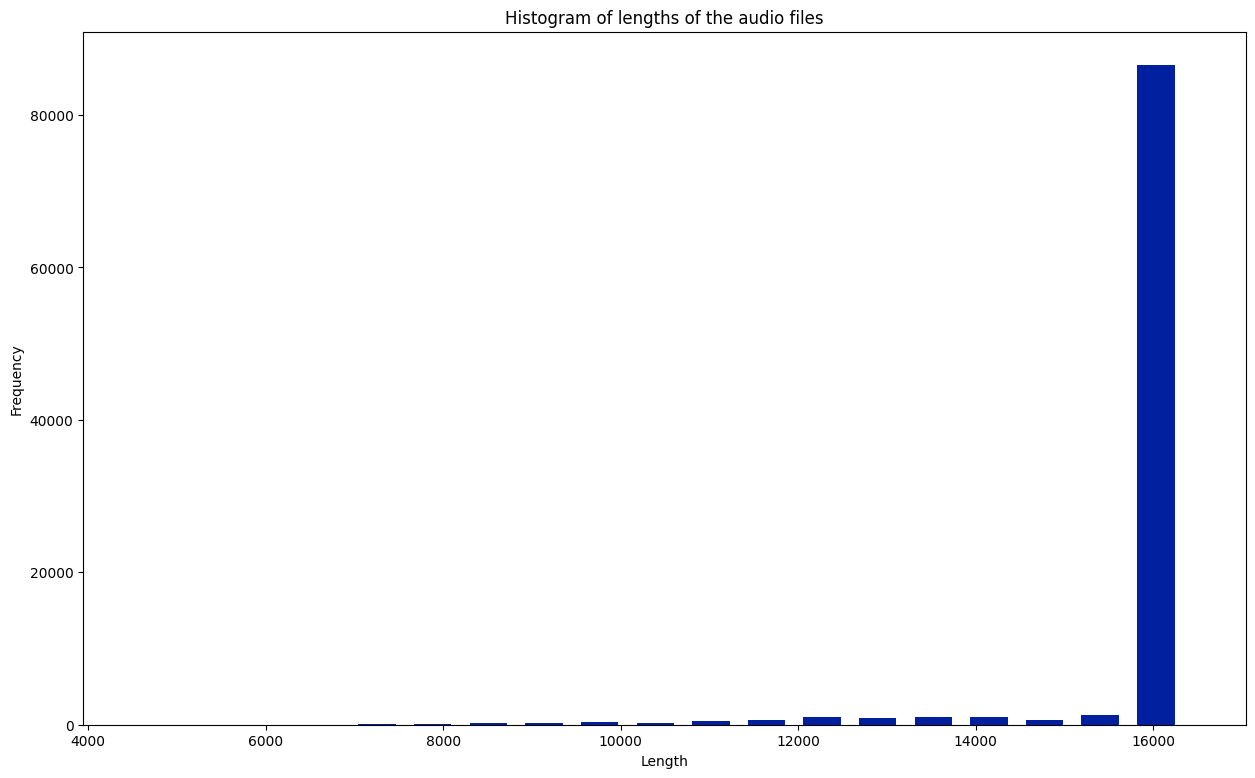

In [5]:
# audio length histogram

lengths = np.array(lengths_tv)
plt.hist(lengths, bins=np.linspace(lengths.min(), lengths.max(), 20, dtype=int), width=8000/19 ,density=False, color=my_blue)
plt.xticks(np.arange(4000, lengths.max()+1, 2000)-8000/18, np.arange(4000, lengths.max()+1, 2000))
plt.title('Histogram of lengths of the audio files')
plt.xlabel('Length')
plt.ylabel('Frequency')
plt.show()

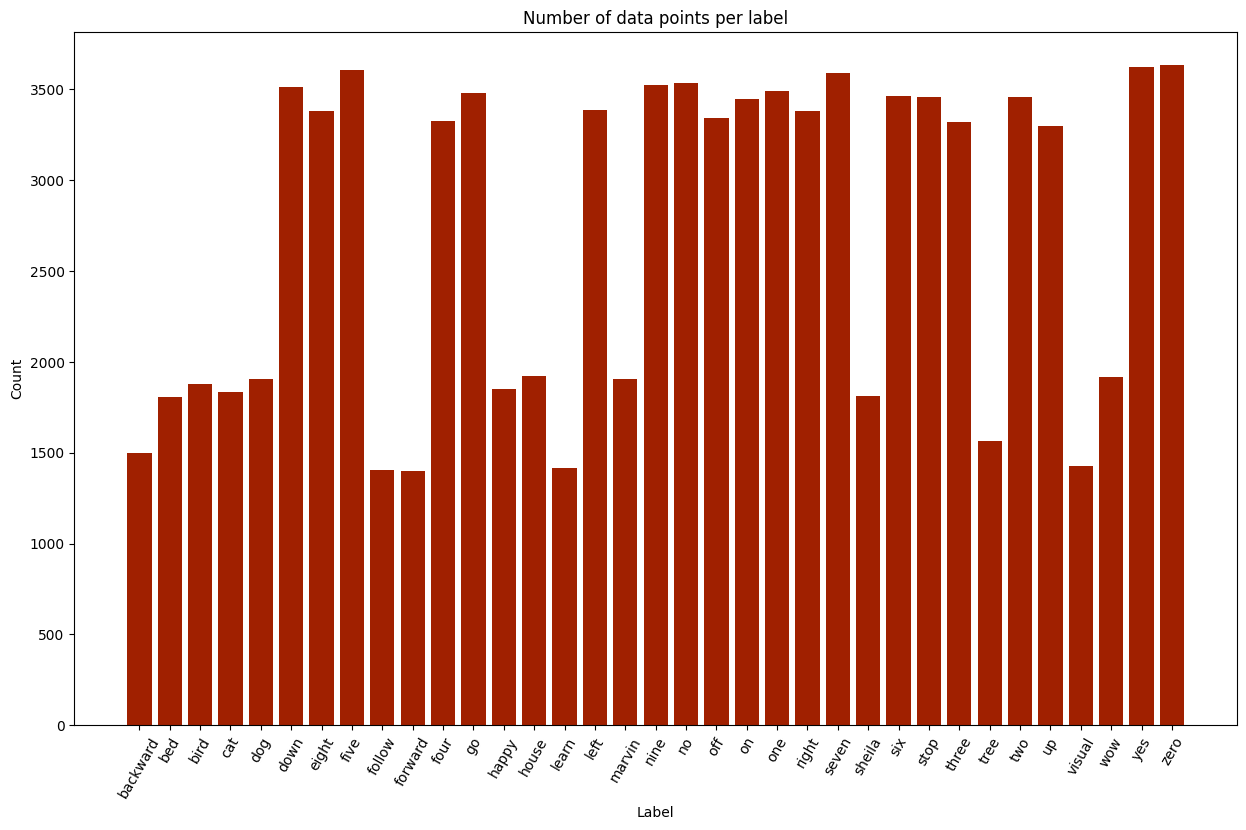

In [6]:
# class distribution

l = np.array(l_tv)
label_count = [np.sum(l == kw) for kw in wordlist]
label_count = np.array(label_count, dtype=np.float32)

plt.bar(range(len(label_count)), label_count, color = my_red)
plt.xticks(range(len(label_count)), wordlist, rotation=60)
plt.xlabel('Label')
plt.ylabel('Count')
plt.title('Number of data points per label')
plt.show()


class_weights = 1 / label_count
class_weights = class_weights / np.max(class_weights)
labels_int = np.arange(n_classes)
class_weights = dict(zip(labels_int, class_weights))

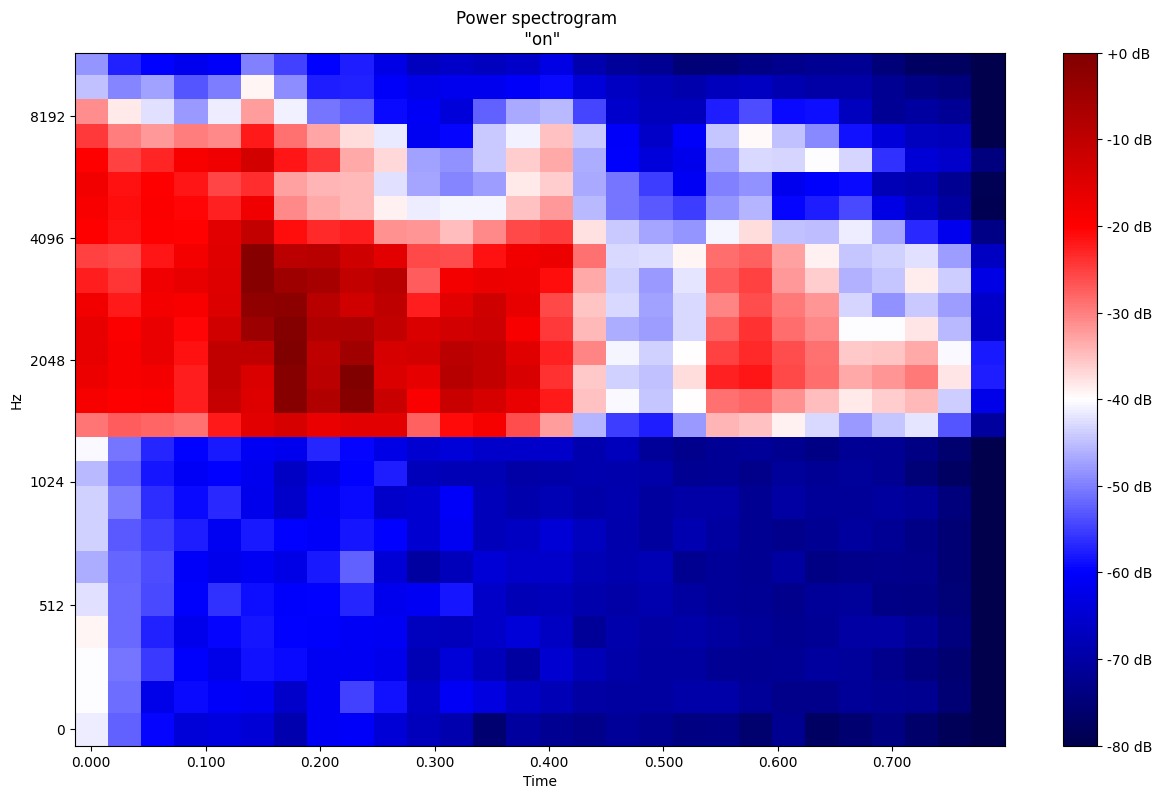

In [7]:
# mel spectrogram sample

ind = np.random.randint(0, X_tv.shape[0])
fig, ax = plt.subplots()
img = librosa.display.specshow(X_tv[ind], y_axis='mel', 
                               x_axis='time', ax=ax, 
                               hop_length = hop_length,
                               cmap='seismic')
ax.set_title('Power spectrogram \n "'+l[ind]+'"')
fig.colorbar(img, ax=ax, format="%+2.0f dB")
plt.show()

# models

### metrics

In [8]:
k = 3
metrics = [keras.metrics.CategoricalAccuracy(name='accuracy'), 
           keras.metrics.Recall(name='recall'), 
           keras.metrics.Precision(name='precision'), 
           keras.metrics.AUC(name='auc'), 
           keras.metrics.F1Score(name='F1'), 
           keras.metrics.TopKCategoricalAccuracy(name=f'top_{k}_accuracy', k=k)]

I0000 00:00:1739642249.984706    5364 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6292 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


### Convolutional layers

In [39]:
# residual blocks to buils a CNN

def residual_block(x, filters):

    shortcut = layers.Conv2D(filters, (1, 1), padding="same")(x)
    shortcut = layers.BatchNormalization()(shortcut)
    x = layers.Conv2D(filters, (3, 3), padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(filters, (3, 3), padding="same")(x)
    x = layers.BatchNormalization()(x)

    # add residual connection
    x = layers.Add()([x, shortcut])
    x = layers.Activation("relu")(x)
    
    return x


def build_cnn(input_shape, n_classes=n_classes, num_residual_blocks=4, dropout=0.5, summary=True):

    input_layer = layers.Input(shape=input_shape)
    x = layers.Conv2D(128, (5, 5), activation='relu')(input_layer)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout)(x)

    for _ in range(num_residual_blocks):
        x = residual_block(x, 32)

    # x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(dropout)(x)
    output_layer = layers.Dense(n_classes, activation='softmax')(x)
    model = keras.Model(inputs=input_layer, outputs=output_layer)

    if summary:
        model.summary()

    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=metrics)

    return model


    

In [ ]:
# optimal parameters

in_shape = X_tv.shape[1:]
n_blocks = 4
model_name = f'Resnet_{n_blocks}_'+ settings

nepoch = 10
CBS = np.logspace(2., 3.4, 5, dtype=int)
niter = 3

early_stopping = EarlyStopping(monitor='val_accuracy', patience=nepoch//2, mode='max', verbose=1)

CNN = build_cnn(input_shape=in_shape, n_classes=n_classes, summary=True)


history_main_cnn = []
for _ in range(niter):
    for mini_batch in CBS:
        print(f'batch_size: {mini_batch}  \n\n\n\n')
        history_main_cnn.append(CNN.fit(X_train, y_train, epochs=nepoch, batch_size=mini_batch, validation_data=(X_val, y_val), verbose=1, callbacks=[early_stopping], class_weight=class_weights))

CBS = niter*list(CBS)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 26, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 22, 24,    │      3,328 │ input_layer[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 22, 24,    │        512 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 22, 24,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 22, 24,    │     36,896 │ dropout[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 22, 24,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 22, 24,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 22, 24,    │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 22, 24,    │      4,128 │ dropout[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 22, 24,    │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 22, 24,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 22, 24,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 22, 24,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 22, 24,    │      9,248 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 22, 24,    │        128 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 22, 24,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 22, 24,    │      9,248 │ activation_2[0][

 Total params: 128,067 (500.26 KB)

 Trainable params: 126,979 (496.01 KB)

 Non-trainable params: 1,088 (4.25 KB)

batch_size: 100  




Epoch 1/10


... (22 outputs left out)

2025-02-15 02:14:17.946588: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_3530', 8 bytes spill stores, 8 bytes spill loads

2025-02-15 02:14:18.486577: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_5743', 404 bytes spill stores, 404 bytes spill loads



38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 813ms/step - F1: 0.9250 - accuracy: 0.9303 - auc: 0.9974 - loss: 0.1202 - precision: 0.9645 - recall: 0.9126 - top_3_accuracy: 0.9758

2025-02-15 02:14:34.880659: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_483', 144 bytes spill stores, 144 bytes spill loads

2025-02-15 02:14:37.452333: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_483', 144 bytes spill stores, 144 bytes spill loads

2025-02-15 02:14:37.484037: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_476', 8 bytes spill stores, 8 bytes spill loads



38/38 ━━━━━━━━━━━━━━━━━━━━ 57s 968ms/step - F1: 0.9250 - accuracy: 0.9303 - auc: 0.9974 - loss: 0.1202 - precision: 0.9645 - recall: 0.9126 - top_3_accuracy: 0.9758 - val_F1: 0.9215 - val_accuracy: 0.9290 - val_auc: 0.9953 - val_loss: 0.2483 - val_precision: 0.9563 - val_recall: 0.9198 - val_top_3_accuracy: 0.9753
Epoch 2/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 14s 359ms/step - F1: 0.9273 - accuracy: 0.9329 - auc: 0.9976 - loss: 0.1173 - precision: 0.9666 - recall: 0.9152 - top_3_accuracy: 0.9762 - val_F1: 0.9277 - val_accuracy: 0.9341 - val_auc: 0.9952 - val_loss: 0.2388 - val_precision: 0.9575 - val_recall: 0.9250 - val_top_3_accuracy: 0.9768
Epoch 3/10
38/38 ━━━━━━━━━━━━━━━━━━━━ 14s 360ms/step - F1: 0.9277 - accuracy: 0.9330 - auc: 0.9975 - loss: 0.1183 - precision: 0.9654 - recall: 0.9144 - top_3_accuracy: 0.9771 - val_F1: 0.9254 - val_accuracy: 0.9322 - val_auc: 0.9951 - val_loss: 0.2409 - val_precision: 0.9543 - val_recall: 0.9225 - val_top_3_accuracy: 0.9760
Epoch 4/10
38/38 ━━━━━━━━━━━━━

In [68]:
# CNN.save('../dumped_models/Resnet_4_5_28_60_40.keras')
# CNN.save('../dumped_models/Resnet_4_5_28_60_40.h5')

CNN = models.load_model('../dumped_models/Resnet_4_5_28_60_40.keras')

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 26, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 22, 24,    │      3,328 │ input_layer_4[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 22, 24,    │        512 │ conv2d_12[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 22, 24,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 22, 24,    │     36,896 │ dropout_6[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 22, 24,    │        128 │ conv2d_14[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 22, 24,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 22, 24,    │      9,248 │ activation_4[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 22, 24,    │      4,128 │ dropout_6[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 22, 24,    │        128 │ conv2d_15[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 22, 24,    │        128 │ conv2d_13[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 22, 24,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 22, 24,    │          0 │ add_2[0][0]       │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 22, 24,    │          0 │ activation_5[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 22, 24,    │      9,248 │ dropout_7[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 22, 24,    │        128 │ conv2d_16[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ batch_normalizat

 Total params: 68,259 (266.64 KB)

 Trainable params: 67,747 (264.64 KB)

 Non-trainable params: 512 (2.00 KB)

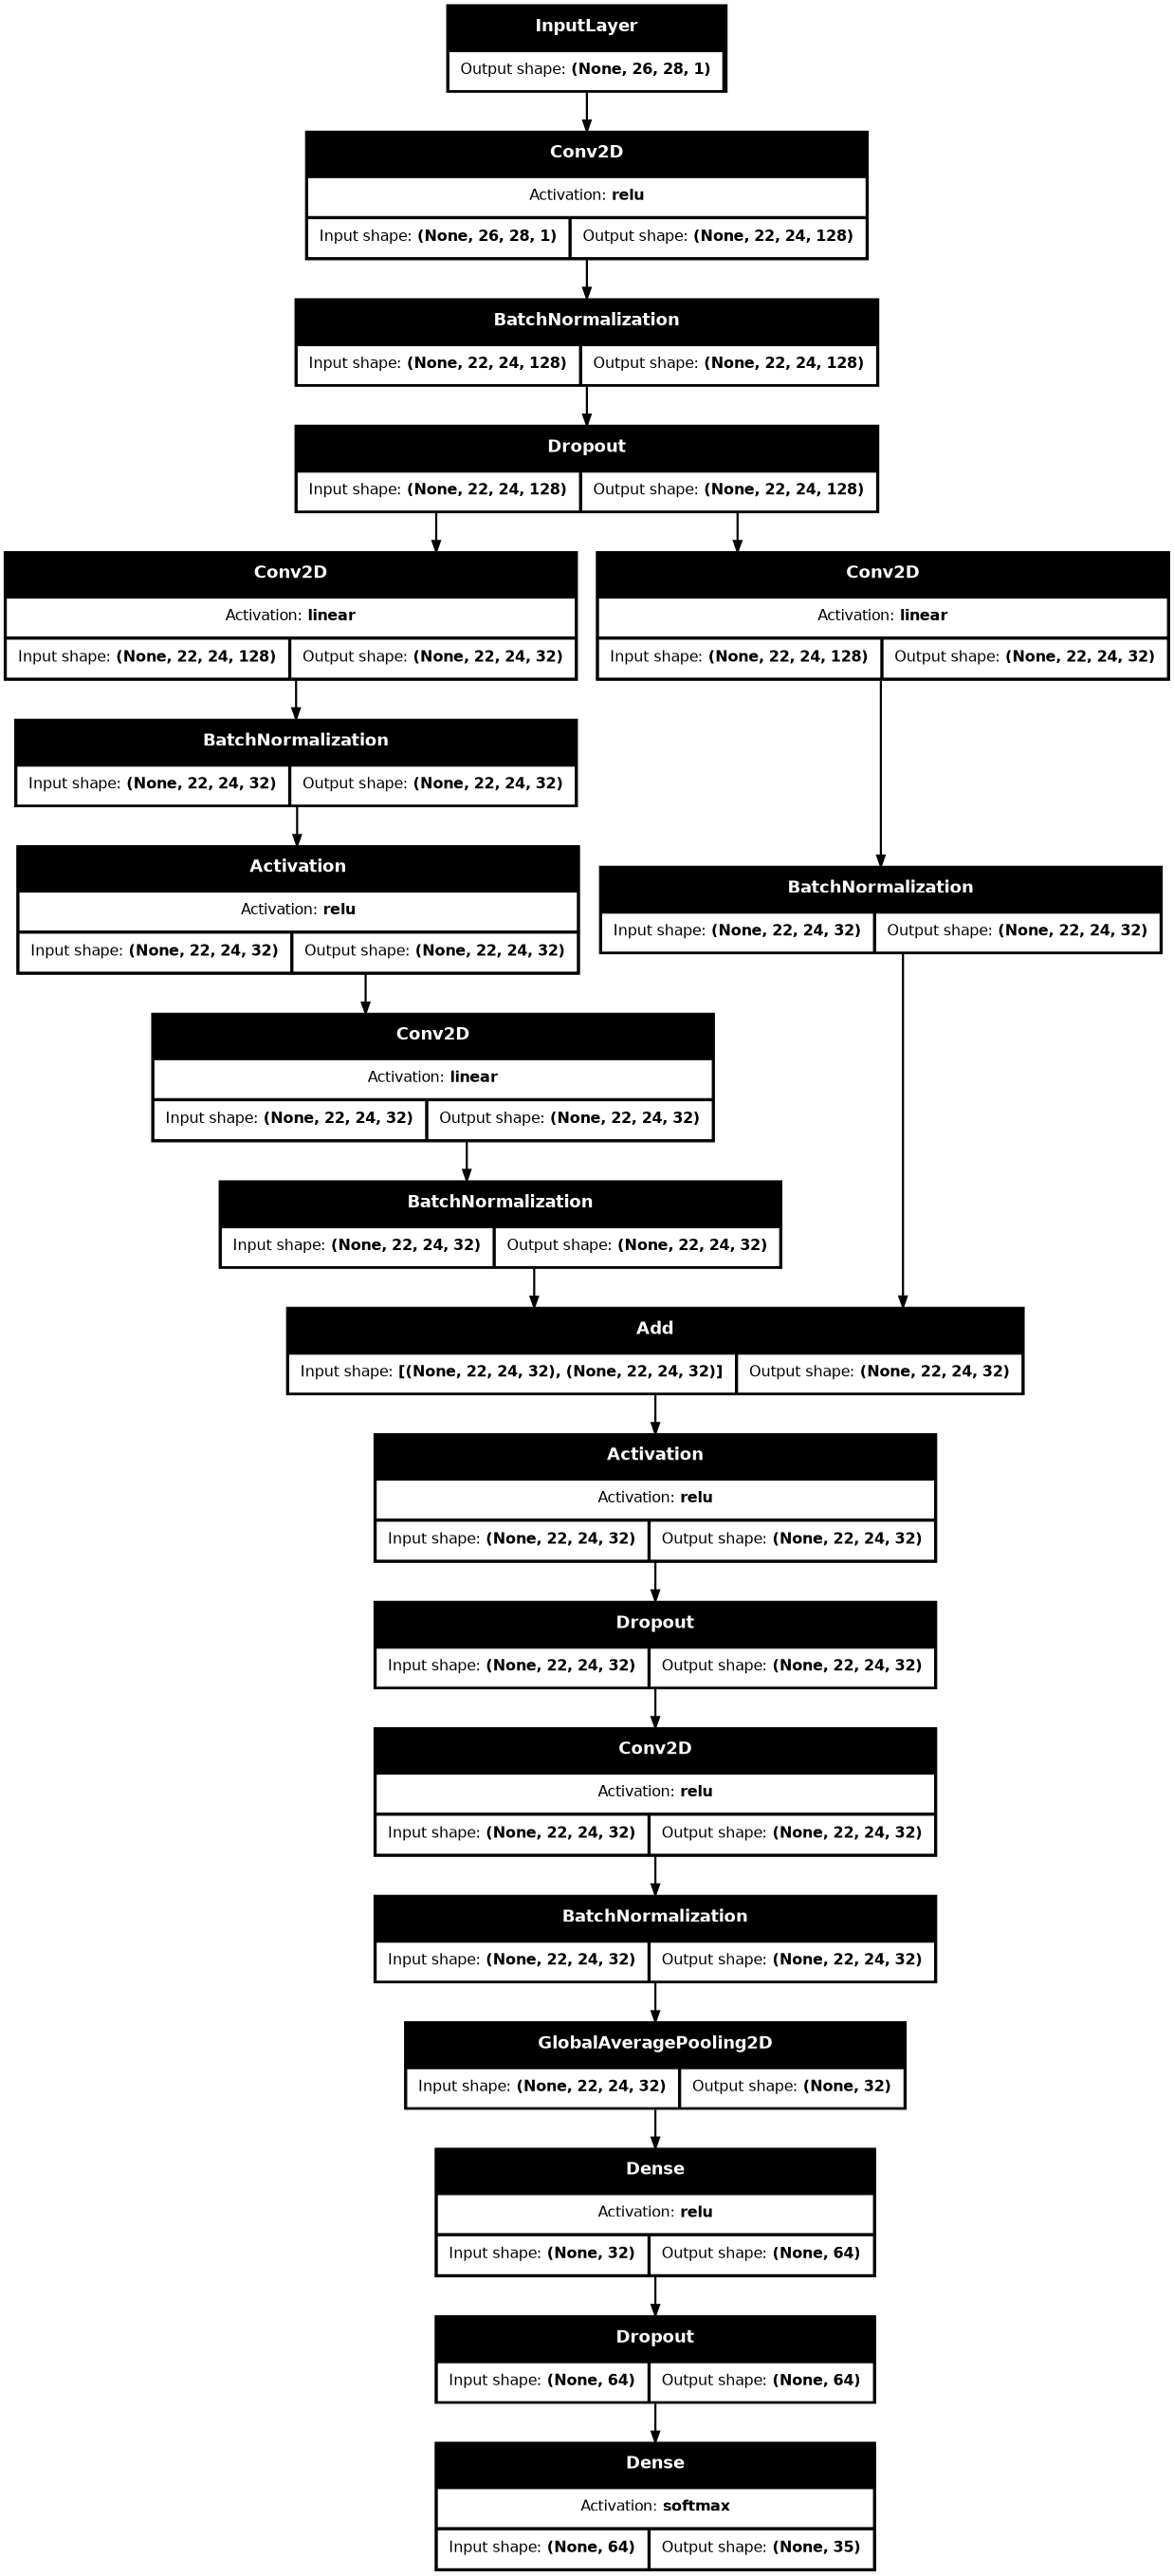

In [40]:
in_shape = X_tv.shape[1:]
cnn_arch_sample = build_cnn(input_shape=in_shape, dropout=0.5, num_residual_blocks=1)

plot_model(cnn_arch_sample, show_shapes=True, show_layer_names=False, dpi=80, show_layer_activations=True,expand_nested=True)

In [75]:
test_eval = CNN.evaluate(X_test, y_test, verbose=0)
test_eval[5] = np.mean(test_eval[5])
metrics_names = ['loss'] + [metric.name for metric in metrics]

results =  pd.DataFrame(data=[test_eval], columns=metrics_names)
results.to_csv('../dumped_models/'+model_name+'.csv',)


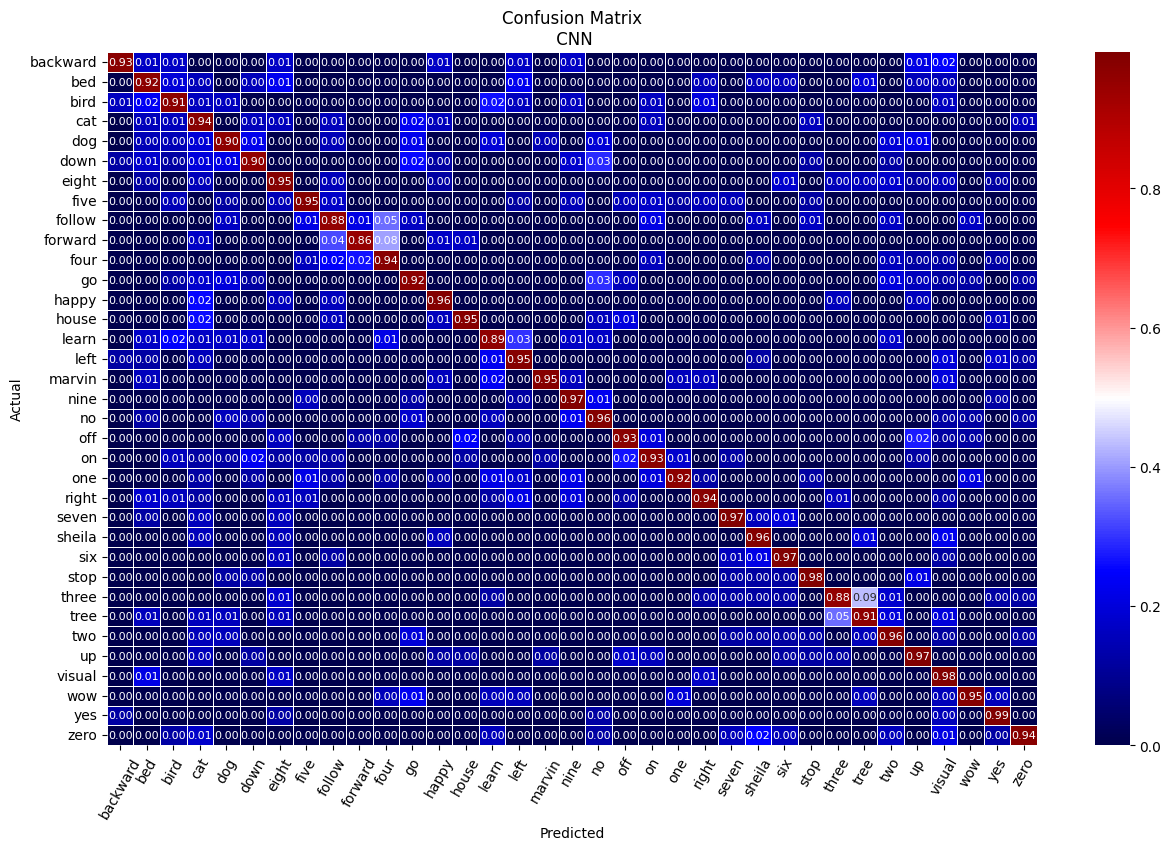

In [70]:
# confusion matrix
y_pred = CNN.predict(X_test, verbose=0)
con_mat = confusion_matrix(np.argmax(y_test,axis=1), np.argmax(y_pred,axis=1), normalize='true')
sns.heatmap(con_mat**0.35, annot=con_mat, fmt='.2f', cmap='seismic', annot_kws={"size": 8}, linewidths=.4)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix\n CNN')
plt.xticks(np.arange(len(label_count))+.5, wordlist, rotation=60)
plt.yticks(np.arange(len(label_count))+.5, wordlist, rotation=0)

plt.show()

In [143]:
%%time

for label in labels:
    label_path = os.path.join(os.path.join(data_dir, 'test_data'), label)
    for filename in os.listdir(label_path):
        if filename.endswith(".wav"):

            mel,_,_ = process_audio_file(os.path.join(label_path, filename), 0)
            mel = mel.T
            mel = mel.reshape((1,mel.shape[0], mel.shape[1]))
            mel = np.array(mel)
            
            pred = CNN.predict(mel,verbose=0)



CPU times: user 15min 7s, sys: 35.7 s, total: 15min 43s
Wall time: 7min 37s


In [8]:
gc.collect()

def get_memory_usage():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

memory_usages = []
samples = np.random.randint(0, len(X_test), 1000)
# X_test = np.expand_dims(X_test, axis=1)
for sample in samples:
    gc.collect()
    K.clear_session()
    memory_before = get_memory_usage()
    pred = CNN.predict(X_test[sample],verbose=0)
    memory_after = get_memory_usage()

    memory_used = memory_after - memory_before
    memory_usages.append(memory_used)

memory_usages = np.sort(memory_usages)[15:-15]
avg_memory = np.mean(memory_usages)
std_memory = np.std(memory_usages)

print("\n==== Memory Usage Statistics ====")
print(f"Average Memory Used: {avg_memory:.2f} MB")
print(f"Standard Deviation: {std_memory:.2f} MB")



==== Memory Usage Statistics ====
Average Memory Used: 0.93 MB
Standard Deviation: 0.32 MB


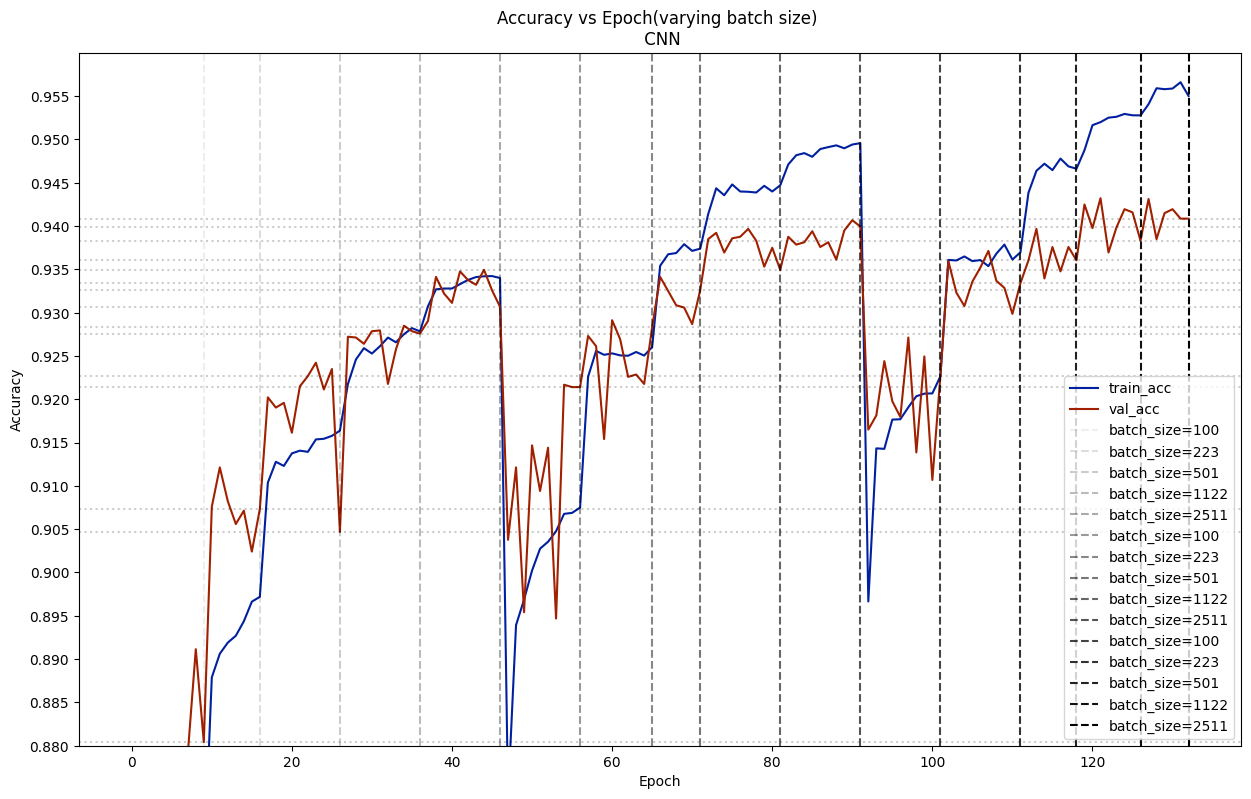

In [25]:
acc = []
val_acc = []
bs_change = []

for hist in history_main_cnn:
    bs_change.append(len(hist.history['accuracy']))
    acc += hist.history['accuracy']
    val_acc += hist.history['val_accuracy']

bs_change = np.cumsum(bs_change)
epoch_ax = np.arange(0, bs_change[-1])
plt.plot(epoch_ax, acc, label='train_acc', color=my_blue)
plt.plot(epoch_ax, val_acc, label='val_acc', color=my_red)
plt.title('Accuracy vs Epoch(varying batch size) \n CNN')
for i in range(len(CBS)):
    plt.axvline(bs_change[i]-1, linestyle='--',color = 'black', alpha=(i+1)/len(CBS), label=f'batch_size={CBS[i]}')
    plt.axhline(val_acc[bs_change[i]-1], linestyle='dotted',color = 'black', alpha=0.2)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim(0.88, .96)
plt.yticks(np.arange(0.88, .96, 0.005))
plt.legend()
plt.show()

### Vanilla RNN

In [19]:
def build_rnn(input_shape, nodes = 200, n_classes = n_classes, depth = 5, mlp_units = [], summary = False):

    if depth < 1:
        raise ValueError("Depth must be greater than or equal to 1")

    input_layer = layers.Input(shape=input_shape)
    
    if depth == 1:
        x = layers.SimpleRNN(nodes, return_sequences=False, activation="relu", dropout=0.)(input_layer)
    
    else:
        x = layers.SimpleRNN(nodes, return_sequences=True, activation="relu", dropout=0.)(input_layer)

        for _ in range(depth - 2):
            x = layers.SimpleRNN(nodes, return_sequences=True, activation="relu", dropout=0.)(x)

        x = layers.SimpleRNN(nodes, return_sequences=False, activation="relu", dropout=0.)(x)

    for units in mlp_units:
        x = layers.Dense(units, activation="relu")(x)
        x = layers.Dropout(0.)(x)
    output_layer = layers.Dense(n_classes, activation="softmax")(x)

    model = models.Model(input_layer, output_layer)
    if summary:
        model.summary()
        
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=metrics)

    return model


#### varying batch sizes

In [ ]:
# increasing batch size

in_shape = X_tv.shape[1:]
rnn = build_rnn(input_shape=in_shape, nodes = 100, n_classes=n_classes, depth = 4, mlp_units=[])
rnn.summary()


nepoch_ibs = 8
IBS = np.logspace(1.8, 3.7, 4, dtype=int)
history_inc_bs = []
for mini_batch in IBS:
    history_inc_bs.append(rnn.fit(X_train, y_train, epochs=nepoch_ibs, batch_size=mini_batch, validation_data=(X_val, y_val), verbose=0))

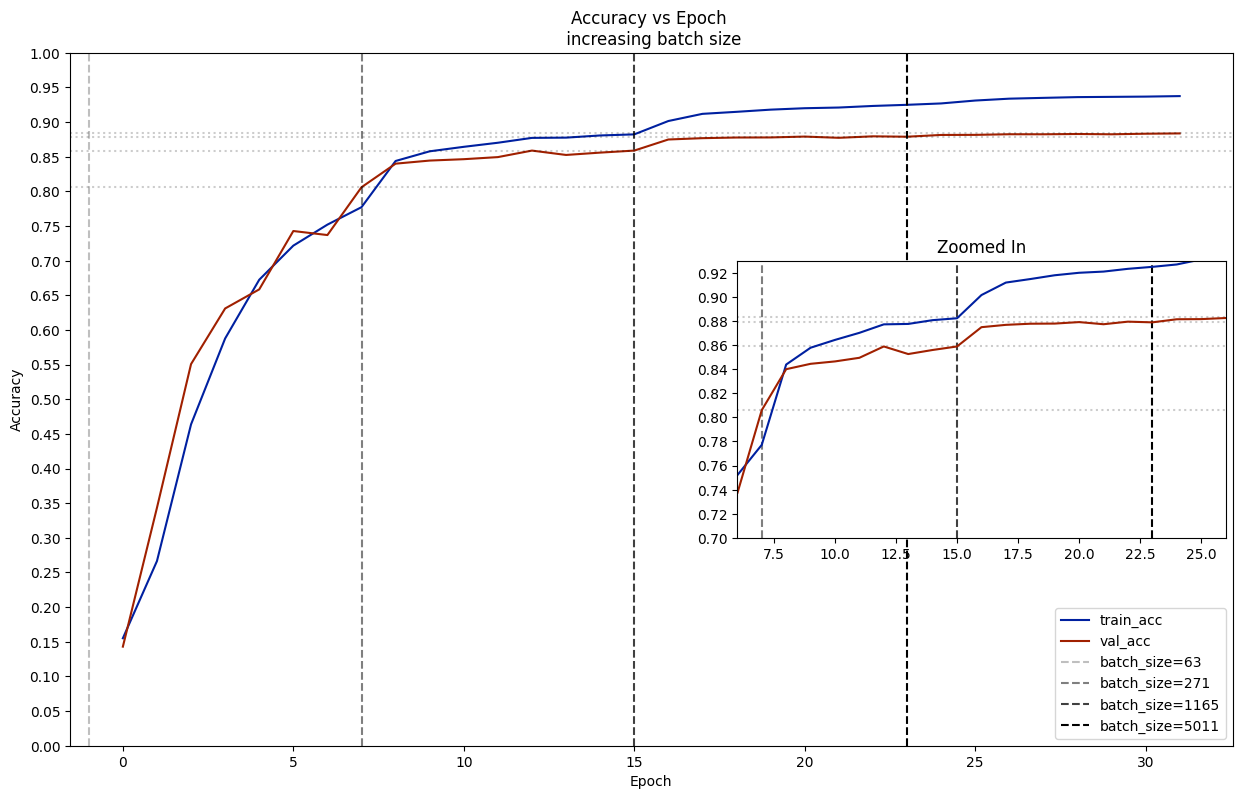

In [153]:
Nepoch = nepoch_ibs * len(IBS)
acc = []
val_acc = []

fig, ax = plt.subplots()
inset_ax = inset_axes(ax, width="42%", height="40%", loc="right")



for hist in history_inc_bs:
    acc += hist.history['accuracy']
    val_acc += hist.history['val_accuracy']

epoch_ax = np.arange(0, Nepoch)
ax.plot(epoch_ax, acc, label='train_acc', color=my_blue)
ax.plot(epoch_ax, val_acc, label='val_acc', color=my_red)
ax.set_title('Accuracy vs Epoch \n increasing batch size')
for i in range(len(IBS)):
    ax.axvline(i*nepoch_ibs-1, linestyle='--',color = 'black', alpha=(i+1)/len(IBS), label=f'batch_size={IBS[i]}')
    ax.axhline(val_acc[i*nepoch_ibs-1], linestyle='dotted',color = 'black', alpha=0.2)

    inset_ax.axvline(i*nepoch_ibs-1, linestyle='--',color = 'black', alpha=(i+1)/len(IBS), label=f'batch_size={IBS[i]}')
    inset_ax.axhline(val_acc[i*nepoch_ibs-1], linestyle='dotted',color = 'black', alpha=0.2)

ax.set_ylim(0., 1.0)
ax.set_yticks(np.arange(0., 1.01, 0.05))
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.legend()

xlim, ylim = (6, 26), (.7, .93)
inset_ax.plot(epoch_ax, acc, color = my_blue)
inset_ax.plot(epoch_ax, val_acc, color = my_red)
inset_ax.set_xlim(xlim)
inset_ax.set_ylim(ylim)
inset_ax.set_yticks(np.arange(ylim[0], ylim[1], 0.02))
inset_ax.set_title("Zoomed In")



plt.show()

In [28]:
# high batch size

in_shape = X_tv.shape[1:]
rnn = build_rnn(input_shape=in_shape, nodes = 100, n_classes=n_classes, depth = 4, mlp_units=[])
rnn.summary()


nepoch = 8
HBS = np.logspace(3.7, 3.7, 26, dtype=int)
history_high_bs = []
for mini_batch in HBS:
    history_high_bs.append(rnn.fit(X_train, y_train, epochs=nepoch, batch_size=mini_batch, validation_data=(X_val, y_val), verbose=0))

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 26, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_12 (SimpleRNN)       │ (None, 26, 100)        │        12,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_13 (SimpleRNN)       │ (None, 26, 100)        │        20,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_14 (SimpleRNN)       │ (None, 26, 100)        │        20,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_15 (SimpleRNN)       │ (None, 100)            │        20,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 35)             │         3,535 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 76,735 (299.75 KB)

 Trainable params: 76,735 (299.75 KB)

 Non-trainable params: 0 (0.00 B)

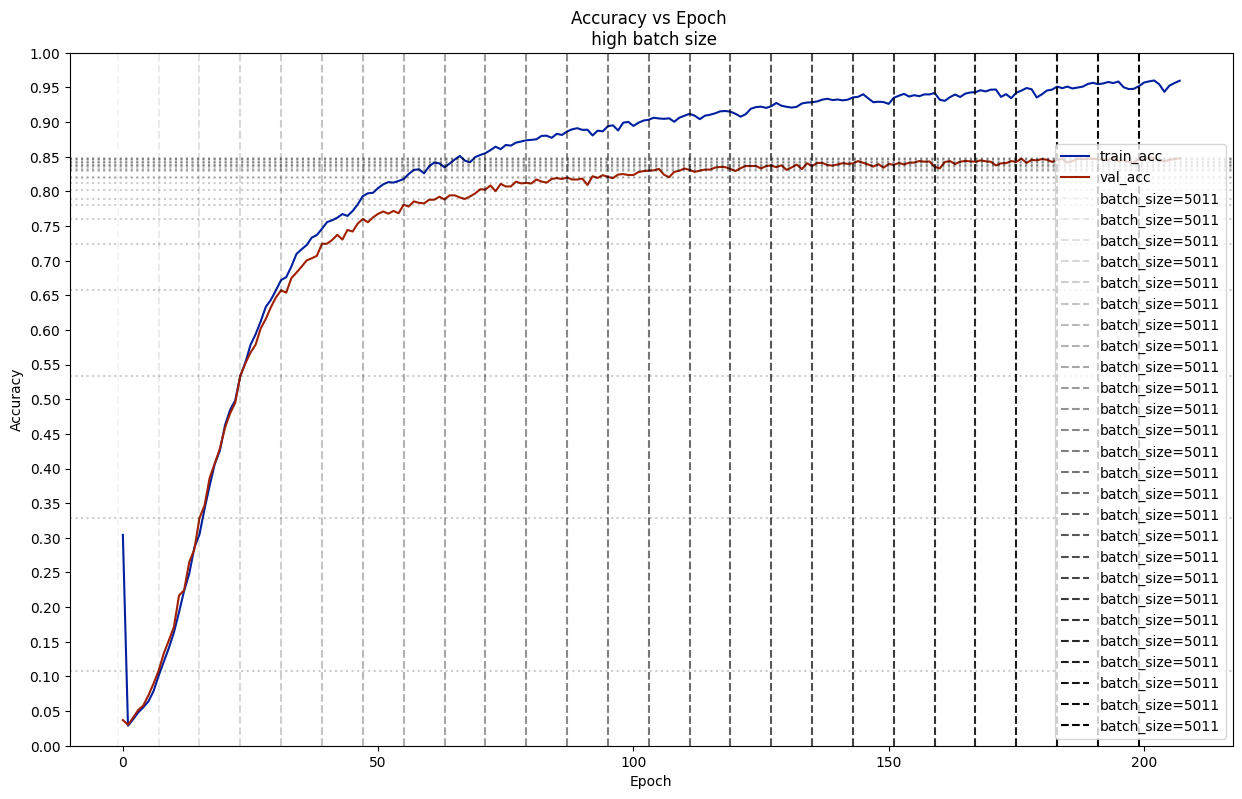

In [33]:
Nepoch = nepoch * len(HBS)
acc = []
val_acc = []

for hist in history_high_bs:
    acc += hist.history['accuracy']
    val_acc += hist.history['val_accuracy']

epoch_ax = np.arange(0, Nepoch)
plt.plot(epoch_ax, acc, label='train_acc', color=my_blue)
plt.plot(epoch_ax, val_acc, label='val_acc', color=my_red)
plt.title('Accuracy vs Epoch \n high batch size')
for i in range(len(HBS)):
    plt.axvline(i*nepoch-1, linestyle='--',color = 'black', alpha=(i+1)/len(HBS), label=f'batch_size={HBS[i]}')
    plt.axhline(val_acc[i*nepoch-1], linestyle='dotted',color = 'black', alpha=0.2)

plt.ylim(0., 1.0)
plt.yticks(np.arange(0., 1.01, 0.05))
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [38]:
# low batch size

in_shape = X_tv.shape[1:]
rnn = build_rnn(input_shape=in_shape, nodes = 100, n_classes=n_classes, depth = 4, mlp_units=[])
rnn.summary()


nepoch = 8
LBS = np.logspace(1.8, 1.8, 2, dtype=int)
history_low_bs = []
for mini_batch in LBS:
    history_low_bs.append(rnn.fit(X_train, y_train, epochs=nepoch, batch_size=mini_batch, validation_data=(X_val, y_val), verbose=0))

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 26, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_24 (SimpleRNN)       │ (None, 26, 100)        │        12,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_25 (SimpleRNN)       │ (None, 26, 100)        │        20,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_26 (SimpleRNN)       │ (None, 26, 100)        │        20,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_27 (SimpleRNN)       │ (None, 100)            │        20,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 35)             │         3,535 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 76,735 (299.75 KB)

 Trainable params: 76,735 (299.75 KB)

 Non-trainable params: 0 (0.00 B)

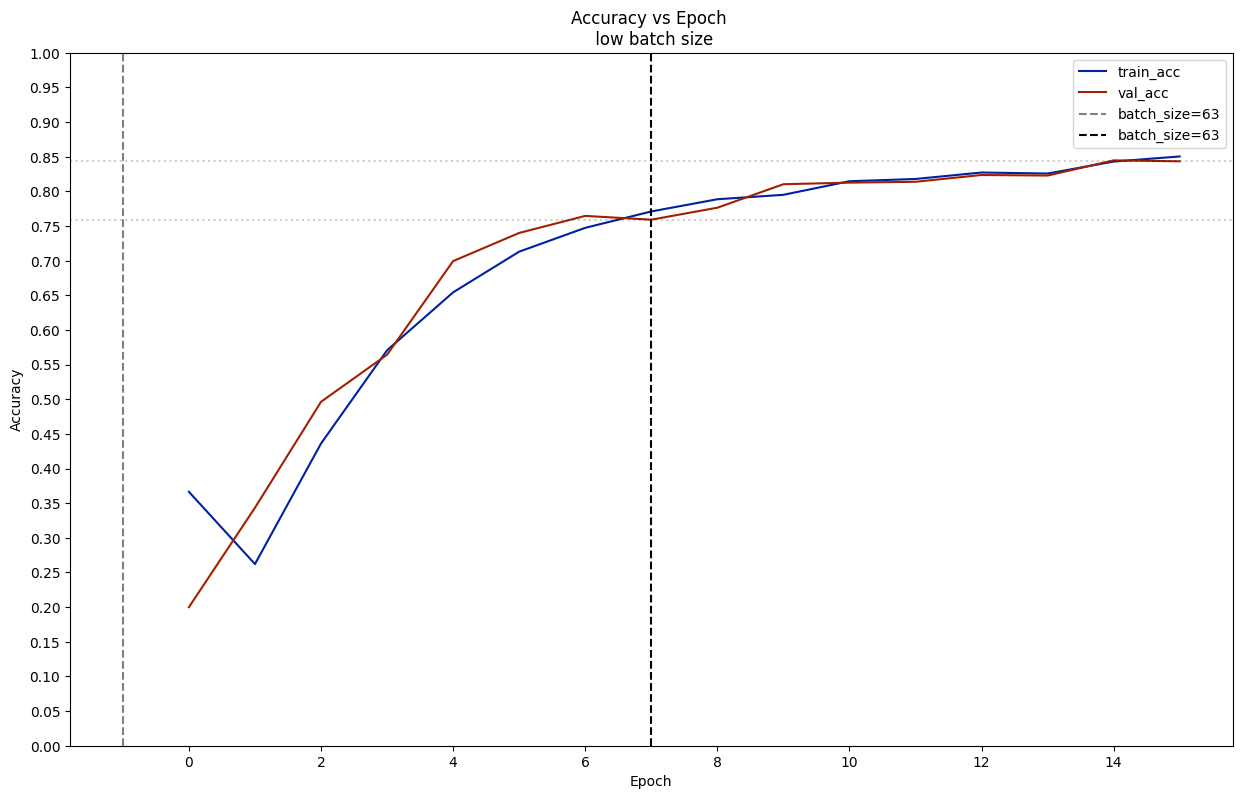

In [ ]:
Nepoch = nepoch * len(LBS)
acc = []
val_acc = []

for hist in history_low_bs:
    acc += hist.history['accuracy']
    val_acc += hist.history['val_accuracy']

epoch_ax = np.arange(0, Nepoch)
plt.plot(epoch_ax, acc, label='train_acc', color=my_blue)
plt.plot(epoch_ax, val_acc, label='val_acc', color=my_red)
plt.title('Accuracy vs Epoch \n low batch size')
for i in range(len(LBS)):
    plt.axvline(i*nepoch-1, linestyle='--',color = 'black', alpha=(i+1)/len(LBS), label=f'batch_size={LBS[i]}')
    plt.axhline(val_acc[i*nepoch-1], linestyle='dotted',color = 'black', alpha=0.2)

plt.ylim(0., 1.0)
plt.yticks(np.arange(0., 1.01, 0.05))
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

#### train test analyze dump

In [20]:
# optimal parameters

nodes = 120
mlp_units = []
depth = 5
in_shape = X_tv.shape[1:]
nepoch = 10
BS = np.logspace(2.2, 4, 5, dtype=int)
niter = 3

early_stopping = EarlyStopping(monitor='val_accuracy', patience=nepoch//2-1, mode='max', verbose=1)

RNN = build_rnn(input_shape=in_shape, nodes = nodes, n_classes=n_classes, depth = depth, mlp_units=mlp_units, summary=True)


history_main = []
for _ in range(niter):
    for mini_batch in BS:
        print(f'batch_size: {mini_batch}  \n\n\n\n')
        history_main.append(RNN.fit(X_train, y_train, epochs=nepoch, batch_size=mini_batch, validation_data=(X_val, y_val), verbose=1, callbacks=[early_stopping], class_weight=class_weights))

BS = niter*list(BS)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 26, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 26, 120)        │        17,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 26, 120)        │        28,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 26, 120)        │        28,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ (None, 26, 120)        │        28,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_4 (SimpleRNN)        │ (None, 120)            │        28,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 35)             │         4,235 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 137,795 (538.26 KB)

 Trainable params: 137,795 (538.26 KB)

 Non-trainable params: 0 (0.00 B)

batch_size: 158  




Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - F1: 0.0413 - accuracy: 0.0460 - auc: 0.5622 - loss: 2.9938 - precision: 0.0849 - recall: 0.0033 - top_3_accuracy: 0.1320 - val_F1: 0.1046 - val_accuracy: 0.1397 - val_auc: 0.7619 - val_loss: 3.2308 - val_precision: 0.3048 - val_recall: 0.0390 - val_top_3_accuracy: 0.3450
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - F1: 0.2391 - accuracy: 0.2591 - auc: 0.8648 - loss: 1.2981 - precision: 0.6053 - recall: 0.0838 - top_3_accuracy: 0.5041 - val_F1: 0.1935 - val_accuracy: 0.1995 - val_auc: 0.7632 - val_loss: 3.9066 - val_precision: 0.3099 - val_recall: 0.1390 - val_top_3_accuracy: 0.4022
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - F1: 0.4501 - accuracy: 0.4680 - auc: 0.9358 - loss: 0.9223 - precision: 0.7234 - recall: 0.2932 - top_3_accuracy: 0.7257 - val_F1: 0.5890 - val_accuracy: 0.6007 - val_auc: 0.9633 - val_loss: 1.3060 - val_precision: 0.7727 - val_recall: 0.4723 - val_top_3_accuracy: 0.8

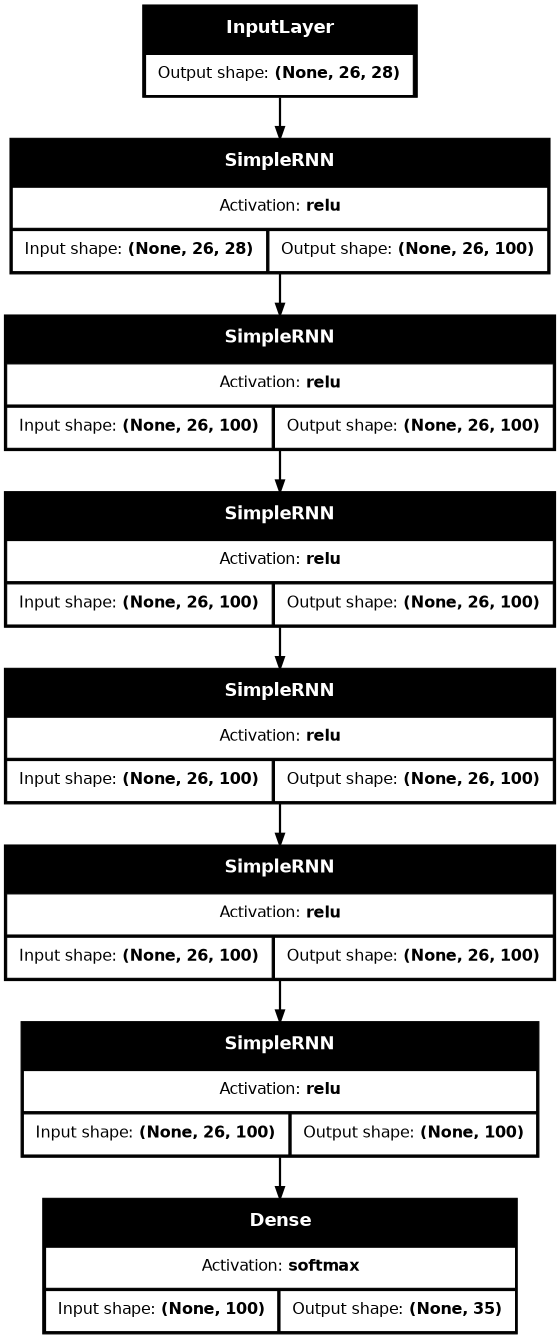

In [ ]:
plot_model(RNN, show_shapes=True, show_layer_names=False, dpi=80, show_layer_activations=True,expand_nested=True)

344/344 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


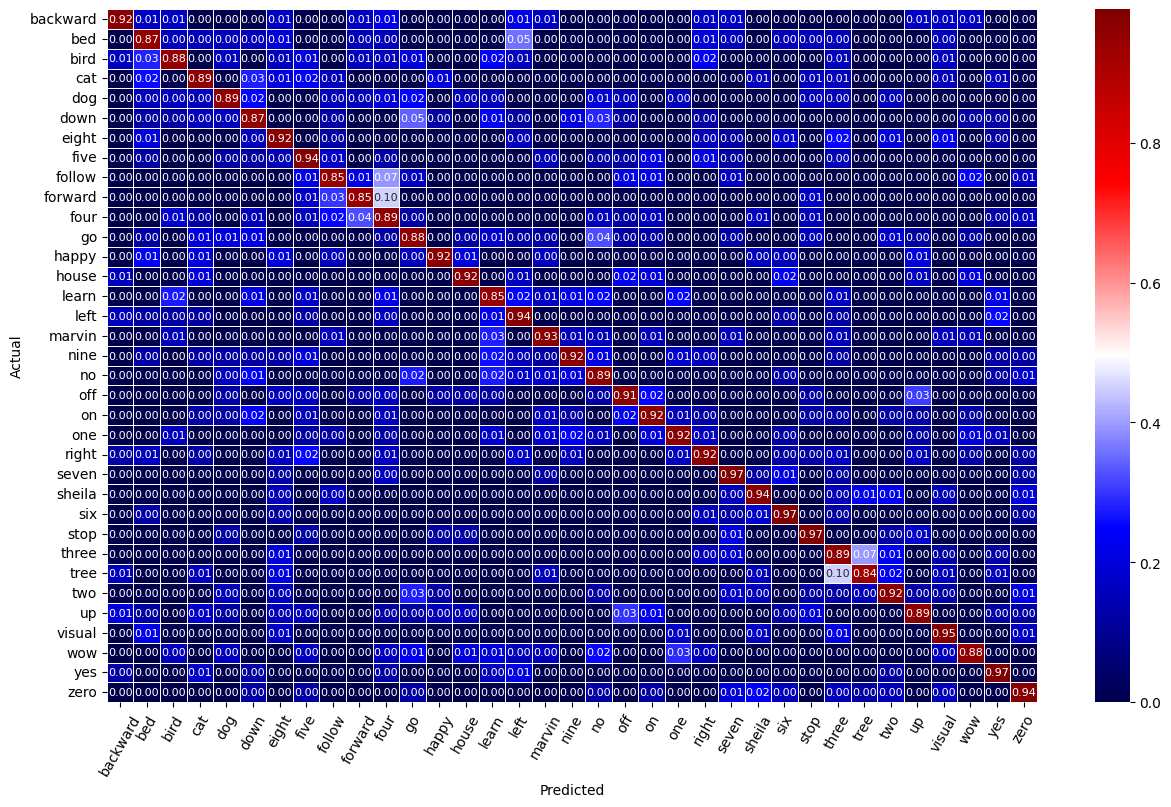

In [149]:
# confusion matrix
y_pred = RNN.predict(X_test)
con_mat = confusion_matrix(np.argmax(y_test,axis=1), np.argmax(y_pred,axis=1), normalize='true')
sns.heatmap(con_mat**0.35, annot=con_mat, fmt='.2f', cmap='seismic', annot_kws={"size": 8}, linewidths=.4)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(np.arange(len(label_count))+.5, wordlist, rotation=60)
plt.yticks(np.arange(len(label_count))+.5, wordlist, rotation=0)

plt.show()

In [156]:
test_eval = RNN.evaluate(X_test, y_test, verbose=0)
test_eval[5] = np.mean(test_eval[5])
metrics_names = ['loss'] + [metric.name for metric in metrics]

results =  pd.DataFrame(data=[test_eval], columns=metrics_names)

results.to_csv('../dumped_models/RNN_120_5_none_28_60_40.csv')


In [150]:
%%time

for label in labels:
    label_path = os.path.join(os.path.join(data_dir, 'test_data'), label)
    for filename in os.listdir(label_path):
        if filename.endswith(".wav"):

            mel,_,_ = process_audio_file(os.path.join(label_path, filename), 0)
            mel = mel.T
            mel = mel.reshape((1,mel.shape[0], mel.shape[1]))
            mel = np.array(mel)
            
            pred = RNN.predict(mel,verbose=0)



CPU times: user 14min 53s, sys: 35.6 s, total: 15min 28s
Wall time: 7min 31s


In [32]:
gc.collect()


def get_memory_usage():
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / (1024 * 1024)

memory_usages = []
samples = np.random.randint(0, len(X_test), 1000)
# X_test = np.expand_dims(X_test, axis=1)
for sample in samples:
    gc.collect()
    K.clear_session()
    memory_before = get_memory_usage()
    pred = RNN.predict(X_test[sample],verbose=0)
    memory_after = get_memory_usage()

    memory_used = memory_after - memory_before
    memory_usages.append(memory_used)

memory_usages = np.sort(memory_usages)[15:-15]
avg_memory = np.mean(memory_usages)
std_memory = np.std(memory_usages)

print("\n==== Memory Usage Statistics ====")
print(f"Average Memory Used: {avg_memory:.2f} MB")
print(f"Standard Deviation: {std_memory:.2f} MB")



==== Memory Usage Statistics ====
Average Memory Used: 1.53 MB
Standard Deviation: 0.59 MB


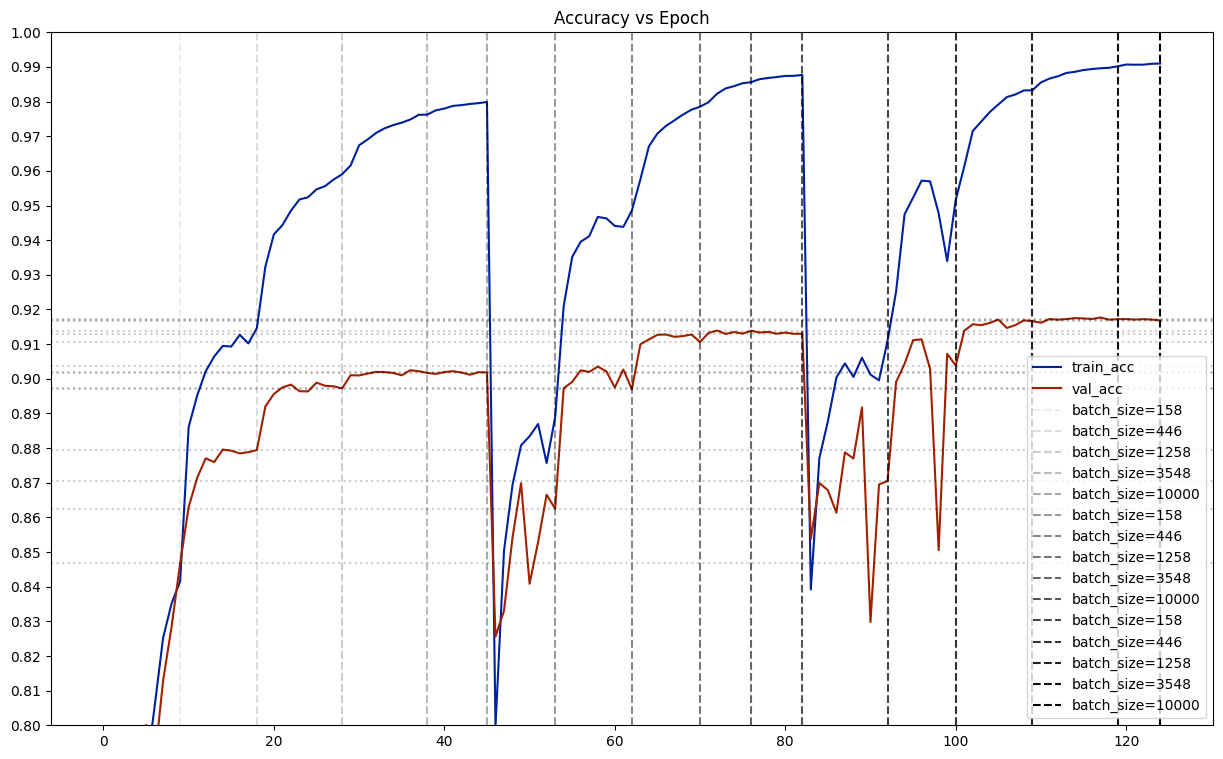

In [147]:
acc = []
val_acc = []
bs_change = []

for hist in history_main:
    bs_change.append(len(hist.history['accuracy']))
    acc += hist.history['accuracy']
    val_acc += hist.history['val_accuracy']

bs_change = np.cumsum(bs_change)
epoch_ax = np.arange(0, bs_change[-1])
plt.plot(epoch_ax, acc, label='train_acc', color=my_blue)
plt.plot(epoch_ax, val_acc, label='val_acc', color=my_red)
plt.title('Accuracy vs Epoch')
for i in range(len(BS)):
    plt.axvline(bs_change[i]-1, linestyle='--',color = 'black', alpha=(i+1)/len(BS), label=f'batch_size={BS[i]}')
    plt.axhline(val_acc[bs_change[i]-1], linestyle='dotted',color = 'black', alpha=0.2)

plt.ylim(0.8, 1.)
plt.yticks(np.arange(0.8, 1.01, 0.01))
plt.legend()
plt.show()

In [69]:
# dumping the model


# filename saving format:
# nodes,depth,mlp,nmels,window(ms),hop(ms)
RNN.save('../dumped_models/RNN_400_5_none_28_60_40.keras')
RNN.save('../dumped_models/RNN_400_5_none_28_60_40.h5')

### ESN

In [51]:
# select a portion of the labels since ESN runs on cpu

num_classes = 15
mask = np.argmax(y_tv, axis=1)<num_classes

y_tv_cut = y_tv[mask]
y_tv_cut = y_tv_cut[:,:num_classes]
X_tv_cut = X_tv[mask]


X_train_cut, X_val_cut, y_train_cut, y_val_cut = train_test_split(X_tv_cut, y_tv_cut, test_size=0.2)


mask = np.argmax(y_test, axis=1)<num_classes
y_test_cut = y_test[mask]
y_test_cut = y_test_cut[:,:num_classes]
X_test_cut = X_test[mask]


In [ ]:
# the reservoir configuration, shape is inferred from input data

units = 2000              # - number of neurons
lr = .09                 # - leaking rate, controls memory decay and long term dependencies
srad = 0.8                 # - spectral radius of W
rcc = 0.7                # - density of reservoir internal matrix

reservoir = Reservoir(units=units, sr =srad , lr=lr, rc_connectivity=rcc, seed=42, activation='relu')
reservoir.run(X_train_cut[0])

np.abs(reservoir._state).std()


np.float64(53.1146541188553)

In [53]:
# training and test data go through the reservoir and the output state is returned

def do_state(dp, reservoir = reservoir):

    reservoir.run(dp, reset=True)
    state = reservoir._state.flatten()
    return state



# Main processing
states = []
with ProcessPoolExecutor() as executor:
    futures = []
    for dp in X_train_cut:
        futures.append(executor.submit(do_state, dp))

    # Collect results
    for future in futures:
        result = future.result()
        if result is not None:
            states.append(result)

states = np.array(states)


test_states = []
with ProcessPoolExecutor() as executor:
    futures = []
    for dp in X_test_cut:
        futures.append(executor.submit(do_state, dp))

    # Collect results
    for future in futures:
        result = future.result()
        if result is not None:
            test_states.append(result)

test_states = np.array(test_states)



In [54]:
# ridge

clf = LogisticRegression(solver='lbfgs', max_iter=300)
clf.fit(states, np.argmax(y_train_cut, axis=1))

/home/kia/Desktop/PoD/myenv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=300)

In [55]:
# training accuracy

preds = [clf.predict(states[i].reshape(1, -1)) for i in range(len(states))]
preds = np.array(preds).flatten()
np.sum(preds == np.argmax(y_train_cut, axis=1))/len(y_train_cut)

np.float64(0.660164155610524)

In [56]:
# validation accuracy

test_preds = [clf.predict(test_states[i].reshape(1, -1)) for i in range(len(test_states))]
test_preds = np.array(test_preds).flatten()
np.sum(test_preds == np.argmax(y_test_cut, axis=1))/len(y_test_cut)

np.float64(0.6480250293312475)

In [57]:
# train a single fully connected layer insead of fittig a ridge

def build_mlp(inp_shape = (units,), n_classes = num_classes, nlayers = 1):


    input_layer = layers.Input(shape=inp_shape)
    x = input_layer
    for _ in range(nlayers-1):
        x = layers.Dense(300, activation='tanh', lora_rank=16)(x)

    output_layer = layers.Dense(num_classes, activation='softmax')(x)
    mlp = keras.Model(input_layer, output_layer)

    mlp.compile(loss='categorical_crossentropy', optimizer='adam', metrics=metrics)
    mlp.summary()

    return(mlp)


In [65]:
mlp = build_mlp()

niter = 4
esnBS = np.logspace(2, 4.2, 4, dtype=int)
history_esn = []

for _ in range(niter):
    for mini_batch in esnBS:
        history_esn.append(mlp.fit(x=states, y=y_train_cut, batch_size=mini_batch, epochs=15, validation_data=(test_states,y_test_cut), verbose=0))

2025-02-15 19:39:21.691087: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_425', 292 bytes spill stores, 420 bytes spill loads

2025-02-15 19:39:21.704137: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_425', 180 bytes spill stores, 180 bytes spill loads

2025-02-15 19:39:21.736534: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_425', 648 bytes spill stores, 648 bytes spill loads

2025-02-15 19:39:22.783070: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_425', 208 bytes spill stores, 256 bytes spill loads

2025-02-15 19:39:26.464668: I external/local_xla/xla/str

In [66]:
mlp.evaluate(test_states,y_test_cut, verbose=0)

[3.7939352989196777,
 0.8052405118942261,
 0.8048494458198547,
 0.8064263463020325,
 0.9159238338470459,
 <tf.Tensor: shape=(10,), dtype=float32, numpy=
 array([0.7710144 , 0.76018095, 0.824468  , 0.8156424 , 0.6902654 ,
        0.79900736, 0.9025893 , 0.8329519 , 0.7398843 , 0.7960525 ],
       dtype=float32)>,
 0.9409464001655579]

# playground

### GS

In [ ]:
def rnn_via_kthp(hp):
    nodes = hp.Choice('nodes', [200])
    depth = hp.Choice('depth', [1, 2, 3, 4, 5, 6])
    mlp_units_strings = hp.Choice('mlp_units', ['', '32', '128, 64, 32'])
    split = mlp_units_strings.split(',')

    if len(split)>1:  
        mlp_units = np.array([int(x) for x in split])
    else:
        mlp_units = np.array([])

    model = build_rnn(input_shape=in_shape, nodes=nodes, depth=depth, mlp_units=mlp_units, summary=False)
    return model



def cnn_via_kthp(hp):

    num_residual_blocks = hp.Choice('num_residual_blocks', [1,2,3,4])
    dropout = hp.Choice('dropout', [0., .25, .5])

    model = build_cnn(input_shape=in_shape, num_residual_blocks=num_residual_blocks, dropout=dropout, summary=False)
    return model



<Functional name=functional, built=True>

In [29]:
rnn_tuner = kt.RandomSearch(
    hypermodel=rnn_via_kthp,
    objective="val_accuracy",
    max_trials=100,
    executions_per_trial=2,
    overwrite=True,
    directory="./RNN_GS",
    project_name="RNN_200_nodes",
)

cnn_tuner = kt.RandomSearch(
    hypermodel=cnn_via_kthp,
    objective="val_accuracy",
    max_trials=15,
    executions_per_trial=2,
    overwrite=True,
    directory="./CNN_GS",
    project_name="CNN_GS",
)


In [30]:
early_stopping = EarlyStopping(monitor='val_loss', patience=15, verbose=0)
GS = cnn_tuner.search(X_train, y_train, epochs=60, validation_data=(X_val, y_val), batch_size=768, callbacks=[early_stopping])

Trial 12 Complete [00h 09m 51s]
val_accuracy: 0.8667329549789429

Best val_accuracy So Far: 0.9095935523509979
Total elapsed time: 02h 34m 02s


In [15]:
gs_dir = "/home/kia/Desktop/PoD/HDA/notebooks/CNN_GS/CNN_GS"
oracle_file = os.path.join(gs_dir, "oracle.json")

# Load Oracle file (contains general tuner info)
with open(oracle_file, "r") as f:
    oracle_data = json.load(f)

trials_data = []

for trial_id in os.listdir(gs_dir):
    trial_file = os.path.join(gs_dir, trial_id, "trial.json")
    
    try:
        with open(trial_file, "r") as f:
            trial_data = json.load(f)

        hparams = trial_data["hyperparameters"]["values"]
        
        metrics = trial_data["metrics"]["metrics"]
        metric_values = {k: v["observations"][0]["value"] for k, v in metrics.items()}

        trial_entry = {"trial_id": trial_id, **hparams, **metric_values}
        trials_data.append(trial_entry)

    except Exception as e:
        continue
        # print(f"Skipping {trial_id} due to error: {e}")

df = pd.DataFrame(trials_data)

# print(df.head())

df.sort_values(by='val_accuracy', ascending=False)

,trial_id,num_residual_blocks,dropout,F1,accuracy,auc,loss,precision,recall,top_3_accuracy,val_F1,val_accuracy,val_auc,val_loss,val_precision,val_recall,val_top_3_accuracy
5,trial_00,4,0.50,[0.9019812345504761],[0.9088748395442963],[0.9961000978946686],[0.3124881833791733],[0.9524962604045868],[0.884570449590683],[0.9676888287067413],[0.9018020629882812],[0.9095935523509979],[0.9937617480754852],[0.32405999302864075],[0.9465165138244629],[0.8950706422328949],[0.9644159078598022]
6,trial_05,3,0.50,[0.8887644410133362],[0.8969335556030273],[0.9952214062213898],[0.3521699905395508],[0.945297509431839],[0.8683134615421295],[0.9639733731746674],[0.8953155279159546],[0.9023170173168182],[0.9938090145587921],[0.3439476490020752],[0.9455268681049347],[0.8837415874004364],[0.9615685939788818]
4,trial_06,3,0.25,[0.9084110260009766],[0.9152510762214661],[0.9969013333320618],[0.2807675451040268],[0.9541728496551514],[0.8947675824165344],[0.9714285731315613],[0.8918744325637817],[0.9011118113994598],[0.9935225546360016],[0.3461567163467407],[0.9396878778934479],[0.8855494260787964],[0.9626834094524384]
10,trial_09,4,0.00,[0.9555069804191589],[0.9590330123901367],[0.9992150366306305],[0.1330425925552845],[0.9783863723278046],[0.9496957957744598],[0.9870284497737885],[0.8850502967834473],[0.8952213227748871],[0.9886688590049744],[0.4061981290578842],[0.9231595993041992],[0.8864684104919434],[0.9613576829433441]
9,trial_10,2,0.25,[0.8960373401641846],[0.9037640988826752],[0.996213972568512],[0.3203873634338379],[0.9472731649875641],[0.8800356686115265],[0.9675914645195007],[0.8841479420661926],[0.8931724429130554],[0.993632048368454],[0.36597761511802673],[0.9357458651065826],[0.8757871687412262],[0.959474503993988]
3,trial_07,2,0.50,[0.8618922233581543],[0.8719477653503418],[0.9933657348155975],[0.4396764487028122],[0.9319793581962585],[0.8350856006145477],[0.9540277421474457],[0.8813537359237671],[0.8904154896736145],[0.99346524477005],[0.3772060424089432],[0.9363445341587067],[0.8707704544067383],[0.9592033624649048]
1,trial_04,4,0.25,[0.9081884622573853],[0.9153159856796265],[0.9969672560691833],[0.28369322419166565],[0.9555156230926514],[0.8952462077140808],[0.9698710143566132],[0.8780466318130493],[0.8868601024150848],[0.9931405782699585],[0.385849267244339],[0.9298405051231384],[0.8678628504276276],[0.9603483080863953]
2,trial_08,1,0.25,[0.8771611452102661],[0.886201024055481],[0.9949685335159302],[0.37826672196388245],[0.9376608729362488],[0.8590168058872223],[0.9611178934574127],[0.87926185131073],[0.8862273693084717],[0.9929769337177277],[0.38789768517017365],[0.9322199523448944],[0.8680586814880371],[0.9572147130966187]
11,trial_01,1,0.50,[0.8110787868499756],[0.8239231109619141],[0.9898370206356049],[0.6008996069431305],[0.9055602550506592],[0.7689218819141388],[0.9359049201011658],[0.8646804094314575],[0.8735273778438568],[0.993718147277832],[0.4266907721757889],[0.9319437742233276],[0.8445720076560974],[0.9531772434711456]
7,trial_03,2,0.00,[0.914350152015686],[0.9203050136566162],[0.9974332451820374],[0.26320652663707733],[0.9590253233909607],[0.901338517665863],[0.9719964563846588],[0.8570159077644348],[0.8672451674938202],[0.990888774394989],[0.45718884468078613],[0.9155047237873077],[0.8465756773948669],[0.9510831832885742]


### plotting zoom in

In [ ]:
Nepoch = nepoch_ibs * len(IBS)
acc = []
val_acc = []

fig, ax = plt.subplots()
inset_ax = inset_axes(ax, width="40%", height="40%", loc="center")



for hist in history_inc_bs:
    acc += hist.history['categorical_accuracy']
    val_acc += hist.history['val_categorical_accuracy']

epoch_ax = np.arange(0, Nepoch)
ax.plot(epoch_ax, acc, label='train_acc', color=my_blue)
ax.plot(epoch_ax, val_acc, label='val_acc', color=my_red)
ax.set_title('Accuracy vs Epoch \n increasing batch size')
for i in range(len(IBS)):
    ax.axvline(i*nepoch_ibs-1, linestyle='--',color = 'black', alpha=(i+1)/len(IBS), label=f'batch_size={IBS[i]}')
    ax.axhline(val_acc[i*nepoch_ibs-1], linestyle='dotted',color = 'black', alpha=0.2)

    inset_ax.axvline(i*nepoch_ibs-1, linestyle='--',color = 'black', alpha=(i+1)/len(IBS), label=f'batch_size={IBS[i]}')
    inset_ax.axhline(val_acc[i*nepoch_ibs-1], linestyle='dotted',color = 'black', alpha=0.2)

ax.set_ylim(0., 1.0)
ax.set_yticks(np.arange(0., 1.01, 0.05))
ax.legend()

xlim, ylim = (10, 50), (.8, 1.)
inset_ax.plot(epoch_ax, acc, color = my_blue)
inset_ax.plot(epoch_ax, val_acc, color = my_red)
inset_ax.set_xlim(xlim)
inset_ax.set_ylim(ylim)
inset_ax.set_title("Zoomed In")


plt.show()

### GS on mel

In [6]:
import gc
gc.collect()

n_blocks = 3
metrics_names = ['loss'] + [metric.name for metric in metrics]

encoder = OneHotEncoder(sparse_output=False)

mel_ax = np.array([10,15,20,30,40])
time_ax = np.array([30,40,60,90])

for n_mels in mel_ax:
    for win_time in time_ax:

        gc.collect()
        try:
            del X_tv, y_tv, X_train, y_train, X_val, y_val, cnnmodel, test_eval, results, process_audio_file, settings
            gc.collect()
        except:
            pass
        
        gc.collect()


        hop_time = win_time*2/3

        win_length=int(sr*win_time/1000)
        hop_length=int(sr*hop_time/1000)
        settings = str(n_mels) + '_' + str(win_time) + '_' + str(hop_time)


        def process_audio_file(filepath, label, 
                       filter=filter, filter_length=sr, n_mels=n_mels, win_length=win_length, hop_length=hop_length, 
                       noise_amp=0.0, noises = noises, noise_lengths=noise_lengths):
    

            audio, sr = librosa.load(filepath, sr=16000, dtype=np.float32)
            length = len(audio)


            if filter and length < filter_length:
                return None  


            if length < filter_length:
                padded = np.zeros(filter_length)
                start = (filter_length - length) // 2
                end = start + length
                padded[start:end] = audio
                audio = padded

            audio = librosa.util.normalize(audio)
            
            if noise_amp:
                ind = np.random.randint(len(noises))
                start = np.random.randint(noise_lengths[ind] - sr)
                substrate = noises[ind][start:start + sr]
                substrate *= noise_amp
                audio += substrate

            mel = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=n_mels, win_length=win_length, hop_length=hop_length)
            mel = librosa.power_to_db(mel, ref=np.max)

            return mel, label, length
        
        X_tv, l_tv, lengths_tv = parallelize(os.path.join(data_dir, 'training_data'))
        y_tv = np.array([lab2int[label] for label in l_tv])
        y_tv = y_tv.reshape(-1, 1)
        y_tv = encoder.fit_transform(y_tv)
        X_tv = X_tv.reshape(X_tv.shape[0], -1, n_mels, 1)
        X_train, X_val, y_train, y_val = train_test_split(X_tv, y_tv, test_size=0.5)
        in_shape = X_tv.shape[1:]

        cnnmodel = build_cnn(in_shape, n_classes, n_blocks ,summary = False)
        cnnmodel.fit(X_train, y_train, epochs=15, batch_size=200, verbose=0)
        cnnmodel.fit(X_train, y_train, epochs=15, batch_size=800, verbose=0)
        cnnmodel.fit(X_train, y_train, epochs=15, batch_size=1600, verbose=0)
        
        test_eval = cnnmodel.evaluate(X_val, y_val, verbose=0)
        test_eval[5] = np.mean(test_eval[5])
        

        results =  pd.DataFrame(data=[test_eval], columns=metrics_names)
        results.to_csv(os.path.join('../', 'mel_gs2', 'cnn_3_'+settings+'.csv'))



I0000 00:00:1739559871.777019  110945 service.cc:148] XLA service 0x73f194002560 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1739559871.777037  110945 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9
2025-02-14 20:04:31.862167: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1739559872.268446  110945 cuda_dnn.cc:529] Loaded cuDNN version 90701
2025-02-14 20:04:33.299781: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_2973', 8 bytes spill stores, 8 bytes spill loads

2025-02-14 20:04:33.307219: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_4568',

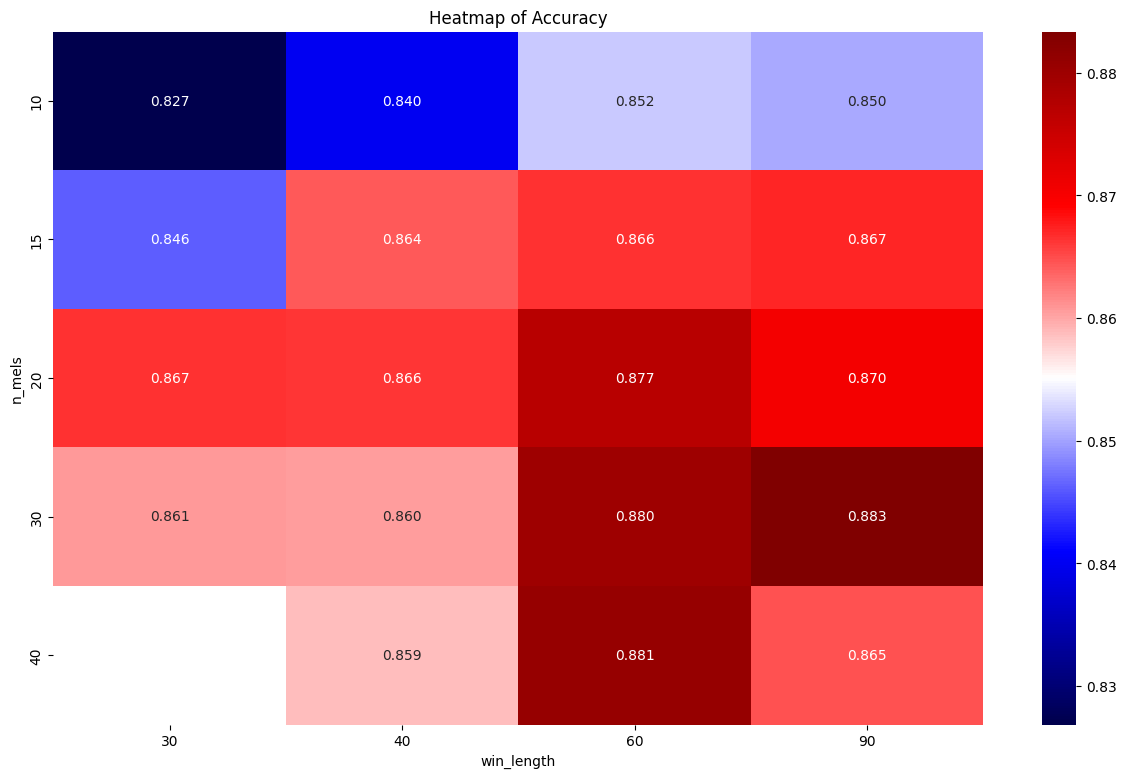

In [ ]:
path = os.path.join('../', 'mel_gs2')

data = []


dirlist = os.listdir(path)

for fname in dirlist:
    if fname.endswith('.csv'):

        v1, v2 = fname.split('_')[2:4]  
        v1, v2 = int(v1), int(v2)

        df = pd.read_csv(os.path.join(path, fname))

        if 'accuracy' in df.columns:
            accuracy = df['accuracy'].mean()
            data.append([v1, v2, accuracy])

grid = pd.DataFrame(data, columns=['v1', 'v2', 'accuracy'])

heatmap_data = grid.pivot(index='v1', columns='v2', values='accuracy')

# plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_data, annot=True, cmap='seismic', fmt=".3f")
plt.xlabel("win_length")
plt.ylabel("n_mels")
plt.title("Heatmap of Accuracy")
plt.show()
